In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

In [2]:
# Carregar os Dados
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [3]:
# Limpeza Básica
# O TotalCharges as vezes vem como texto com espaço vazio, vamos arrumar para número
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dropna(inplace=True) # Remove as linhas nulas

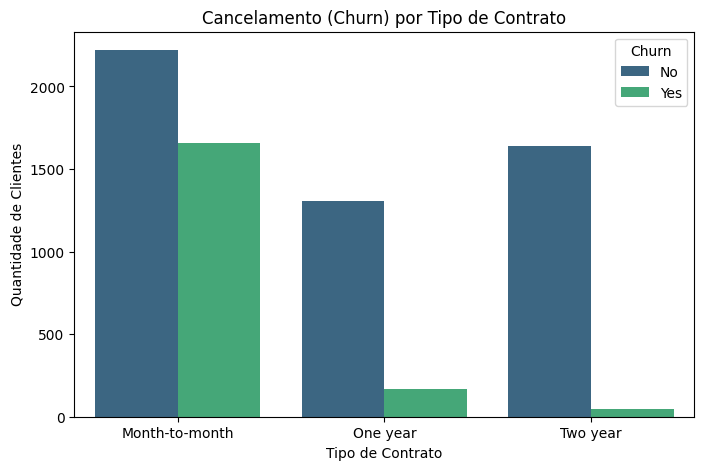

In [4]:
# Análise Exploratória
# Vamos ver qual tipo de contrato cancela mais
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Contract', hue='Churn', palette='viridis')
plt.title('Cancelamento (Churn) por Tipo de Contrato')
plt.xlabel('Tipo de Contrato')
plt.ylabel('Quantidade de Clientes')
plt.show()

In [5]:
# Modelagem de Machine Learning
# O modelo precisa de números, então vamos transformar "Yes"/"No" em 1 e 0.
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

In [6]:
# Selecionar variáveis que vamos usar para prever
features = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'PaymentMethod']
X = pd.get_dummies(df[features]) # Transforma texto (Contrato) em número
y = df['Churn']

In [7]:
# Separar em Treino (70%) e Teste (30%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [8]:
# Treinar a Máquina (Árvore de Decisão)
modelo = DecisionTreeClassifier(max_depth=4, random_state=42)
modelo.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [9]:
# Avaliar
previsoes = modelo.predict(X_test)
print("\n--- Relatório de Performance do Modelo ---")
print(classification_report(y_test, previsoes))


--- Relatório de Performance do Modelo ---
              precision    recall  f1-score   support

           0       0.82      0.90      0.86      1549
           1       0.62      0.45      0.52       561

    accuracy                           0.78      2110
   macro avg       0.72      0.67      0.69      2110
weighted avg       0.76      0.78      0.77      2110

